<a href="https://colab.research.google.com/github/mithran1moses-dotcom/Team-Helble-WACC-/blob/main/Copy_of_HW8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Fragility: SVB, and Who's Next



## Team Helble

#### Marc Chammas, Mithran Moses, Lucas Koranda, Riley Stone

## Question:
##### When Silicon Valley Bank failed on March 10, 2023, did publicly traded U.S. banks with higher uninsured deposit shares and larger unrealized securities losses suffer steeper stock market drops, and which listed banks look most vulnerable on those same measures today?

###Reasoning/Rational for Question Choice

Silicon Valley Bank’s collapse mattered well beyond one bank. It shook U.S. financial markets and hit the tech sector that relied on SVB. We wanted to study it with an event study to see which measurable traits, such as uninsured deposits and bond losses, separated the banks the market punished from the ones it didn’t, and whether those traits could help flag other banks that look like SVB.

##Who and How We Benefit from the Answer

**Bank supervisors(Federal Reserve, FDIC, OCC)**: Supervisors often have limited examining time, resulting in a delegated system to decide which banks to look at first. SVB’s failure is a prime example when that ordering system is wrong. A bank with mostly uninsured deposits has no deposit insurance holding its customers to them. Those types of depositors can leave within hours if they so choose. Banks with large unrealized losses on bonds have to end up selling at a loss to meet withdrawals. This turns paper losses into real ones. A method that finds banks with both traits can tell supervisors where a run is most likely to start. This is important beyond one single bank. A failure one specific bank can push depositors to pull money from similar ones. In March 2023, it was observed that this pattern of behavior led regulators to step in with a federal backstop for all depositors. The sooner a supervisor can see the risk, the more money they save. They can proactivly push to raise capital and change liquidity requirements through exams, before it becomes an emergency that costs the deposit insurance fund and taxpayers more.

**Institutional bank investors and risk managers:**  A few risks play into repricing including a deposit run, and mark-to-market solvency risk. SVB had both at once and its stock lost most of its value within a one to two days. An investor could flagg the combination from public call reports and could have had time to cut the position, hedge it, or demand a higher return for holding it. Risk managers at funds, banks and insurers face the same problem because they hold many banks at once and need to see which ones move together in a panic.


TEAM HYPOTHESIS AND THOUGHTS



## Necessary Data

##### **Unit of Observation**: A singular publicly traded U.S. Bank Holding Company (`bhc_rssd`).
*Rational*: Stock tickers belong to the parent holding company while quarterly Call Reports are filed by individual bank subsidiaries. To derive this number, we sum subsidiary balance sheets up to `bhc_rssd` first and compute financial ratios afterward. (ex. 12 holding companies in v0 aggregate 21 underlying bank subsidiaries).

| Column | Role | Definition |
|---|---|---|
| `ticker`, `bhc_rssd` | Identifiers | Stock ticker and unique Federal Reserve holding company ID |
| `uninsured_dep_share` | Key Predictor | Uninsured deposits divided by total deposits |
| `unreal_loss_to_adj_equity` | Key Predictor | Main loss measure: $(\text{HTM loss} + \text{AFS loss}) / (\text{Book equity} + \text{AFS loss})$ |
| `htm_loss_to_equity` | Robustness | Held-to-maturity securities loss divided by book equity |
| `total_assets` | Control | Total consolidated bank assets (entered as `log_total_assets`) |
| `car_0_2` | Outcome | Cumulative abnormal stock return summed over March 9, 10, and 13, 2023 |

*Accounting note:* Both HTM and AFS losses count in the numerator because both become a real loss if a run forces the bank to sell. We added AFS losses back to book equity in the denominator because GAAP equity already subtracts them. This is so each loss is only counted once (Jiang, Matvos, Piskorski & Seru, 2023).

### Real Sample Rows from  v0 Dataset ($ in Thousands)

| ticker | total_assets | uninsured_dep_share | unreal_loss_to_adj_equity | htm_loss_to_equity | car_0_2 |
|---|---:|---:|---:|---:|---:|
| SIVB | 209,026,000 | 0.939 | 0.983 | 0.981 | −0.571 (day 0 only) |
| JPM | 3,202,004,920 | 0.536 | 0.150 | 0.121 | −0.017 |
| ZION | 89,544,919 | 0.498 | 0.232 | −0.023 | −0.358 |

Zions is the only bank in the sample with a negative HTM loss. This shows its held-to-maturity bonds were worth slightly more than cost. Have to keep this sign instead of rounding it up to zero because the gain is small next to its $1.6 billion in AFS losses.

### Sample Period
* **Primary event window (MVP):** **March 9, 10, and 13, 2023** Trading days `0` to `+2` . Day 0 captures SVB's initial stock collapse whereas Day +1 captures its FDIC seizure on March 10. Day +2 captures the Monday market reaction to Signature Bank's Sunday closure and federal backstop. It stops before Credit Suisse's crisis on March 15.
* **Stretch event window:** **May 1, 2023** First Republic Bank's failure, paired with `03/31/2023` (Q1 2023) Call Reports.
* **Estimation window:** **Calendar year 2022**. Daily market model against `SPY`.
* **Balance-sheet snapshot dates:** **`12/31/2022` (Q4 2022)** for the March 2023 event study, and **`09/30/2026` (Q3 2026)**. These are the latest published quarterly filings for the live current-day fragility screen.

### Sample Conditions
* **Industry & listing status:** Publicly traded U.S. bank holding companies matched between FFIEC regulatory filings and CRSP equity returns.
* **Sample scale:** A 12-bank verification sample (`JPM`, `BAC`, `WFC`, `USB`, `PNC`, `TFC`, `FITB`, `KEY`, `ZION`, `WAL`, `CMA`, `SIVB`) in v0. Expands to all eligible listed U.S. banks (~100 banks) for the full analysis.
* **Asset reporting cutoff:* **Asset reporting cutoff:** Only banks with at least $/$1 billion in total assets report uninsured deposits on Call Reports, so banks below $/$1 billion have no uninsured deposit data.
* **Return history & liquidity:** Banks must have complete 2022 daily return history to estimate market-model betas, plus minimum market-cap and trading-volume filters so thinly traded micro-cap stocks do not add noise.

### Must-Have and Nice-to-Have Variables
* **Must-have variables:** We need to collect data on daily bank stock returns, `SPY` daily market returns, uninsured deposits, total deposits. Also track HTM and AFS amortized cost and fair value, book equity, and total assets.
* **Nice-to-have variables:** It would be good to have market capitalization and average daily dollar trading volume (to filter out illiquid micro-cap banks) and a second event window around First Republic's collapse on May 1, 2023.

### Data Possessed and Needing Aquisition
* **What we have:** Q4 2022 (`12/31/2022`) FFIEC Call Reports, the NY Fed CRSP–FRB crosswalk, FFIEC NIC bank-to-holding-company link tables, and daily CRSP returns (including delisted banks) for our 12-bank v0 sample.
* **What we need:** The full cross-section of ~100 listed bank tickers from CRSP for the MVP, Q1 2023 (`03/31/2023`). We also need to aquire call Reports if adding the First Republic stretch event, and the latest **Q3 2026 (`09/30/2026`)** FFIEC Call Report bulk download for the live dashboard screen.

### Plan to Collect Data Moving Forward
* **Balance sheets:** Download the free single period Call Reports (Tab-Delimited file) bulk zip files directly from the FFIEC Central Data Repository (`cdr.ffiec.gov/public/pws/downloadbulkdata.aspx`) for `12/31/2022` and `09/30/2026`.
* **Regulatory-to-equity links:** Pull the FFIEC NIC attributes file and the NY Fed CRSP–FRB link crosswalk (`newyorkfed.org/research/banking_research/crsp-frb`) to map subsidiary `RSSD` IDs to parent `bhc_rssd` and stock `PERMNO`.
* **Stock returns:** Query CRSP daily stock files via Wharton Research Data Services (WRDS), which retains delisted banks (SIVB, SBNY, FRC, PACW, CMA) so failed institutions are not dropped. Stocks are matched by PERMNO via PERMCO (Can never be by ticker as delisted tickers can be reused) and benchmarked against SPY (PERMNO 84398) from CRSP. This includes CRSP delisting returns.

### Raw Imputs and Storage

| Raw Input | File Format & Source | Location in Repo |
|---|---|---|
| Quarterly Call Reports (`12/31/2022`, `09/30/2026`) | Tab-delimited `.txt` schedules (FFIEC CDR) | `inputs/call_reports/` |
| Bank-to-BHC & Ticker Crosswalks | `.csv` link tables (FFIEC NIC & NY Fed) | `inputs/links/` |
|Daily Bank & SPY (PERMNO 84398) Returns | .parquet/.csv extracts (CRSP via WRDS, matched by PERMNO, with delisting returns) | `inputs/prices/crsp/`(licensed, gitignored)|

---

\## Method & Transformation Pipeline

### High-Level Pipeline (`python run_all.py`)
Running `python run_all.py` rebuilds every intermediate table, regression output, and chart from scratch:

| Step | Script in `code/` | Transformation |
|---|---|---|
| 1 | `01a_download_nyfed_link.py`, `01b_build_link_table.py` | Map each stock ticker (`PERMNO`) to its parent `bhc_rssd` and collect all child bank subsidiaries (`12 BHCs -> 21 subsidiaries` in v0) |
| 2 | `02_build_bank_measures.py` | Sum subsidiary Call Reports to `bhc_rssd` and compute `uninsured_dep_share`, `unreal_loss_to_adj_equity`, and `htm_loss_to_equity` |
| 3 | `03_download_crsp.py` | Pull 2022–2023 daily returns (including delisting returns) for sample banks and `SPY` via WRDS |
| 4 | `04_event_study.py` | Fit 2022 market-model betas against `SPY`, drop CRSP no-trade days (`price < 0`), and sum abnormal returns into `car_0_2` |
| 5 | `05_build_analysis_sample.py` | Merge `12/31/2022` balance-sheet ratios with `car_0_2` into one clean row per BHC |
| 6 | `06_regression.py` | Estimate the cross-sectional regression and export `outputs/regression_main.csv`, `regression_main.txt`, and `outputs/figures/scatter_loss_vs_car.png` |
| 7 | `07_current_screen.py` *(planned)* | Apply Step 2 fragility ratios to the `09/30/2026` Call Report for the live dashboard screen |

### Statistical Model & Why It Fits
Estimate the cross-sectional regression with heteroskedasticity-robust (HC1) standard errors(type of adjusted standard error used in regression analysis to to ensure valid hypothesis testing):

$$
\text{CAR}_i = \alpha + \beta_1\,\text{UninsuredShare}_i + \beta_2\,\text{LossRatio}_i + \beta_3\,\log(\text{TotalAssets}_i) + \varepsilon_i
$$

####Rational for setting up a tight three-day cross-sectional regression
Short windows isolate the market’s reaction to the run from everything else going on. Over three days, banks’ balance sheets are fixed at their 12/31/2022 values. Management during this time has no time to raise capital or sell bonds. The differences in returns across banks reflect mostly how investors judged each bank’s existing exposure. A longer window could possibly mix that reaction with new information. Things like the Credit Suisse shock, policy responses, and banks changing their own positions. We need to compare banks against each other in a cross-section because the question is which banks were punished more. The regression looks at whether uninsured share and bond losses line up with that difference, after controlling for size.




## Threats & Auditor Checks

| Potential Auditor Critique | How Our Design Handles It |
|---|---|
| **Call-report timing / look-ahead bias** | Event-study predictors come strictly from `12/31/2022` filings (and `03/31/2023` for the May 1 First Republic stretch event), ensuring zero post-shock information leaks into predictors. |
| **ID link quality** | We join FFIEC NIC subsidiary-to-parent files with the NY Fed CRSP–FRB crosswalk, report the exact match rate, and manually verify a subsample against SEC 10-K filings. |
| **Small, illiquid banks with noisy returns** | Banks under $\$1\text{B}$ are excluded because they do not report uninsured deposits, and we apply minimum market-cap and volume filters logged in `specs_tried.md`. |
| **Survivorship bias** | Switching from `yfinance` to CRSP via WRDS retains delisted and failed banks (`SIVB`, `SBNY`, `FRC`, `PACW`, `CMA`) in the sample. |
| **SIVB trading halt after March 9** | `SIVB` had no trades on March 10 (`price < 0` in CRSP) prior to FDIC receivership, so `04_event_study.py` drops March 10 and `SIVB`'s CAR reflects day 0 only. We flag `SIVB` and report regressions **with and without `SIVB`**. |
| **Partial subsidiary reporting** | Only bank subsidiaries with at least $1 billion in assets report uninsured deposits, but total deposits are summed over every subsidiary. A holding company with a non-reporting subsidiary (JPM, CMA and WFC in v0) can therefore have its uninsured share understated. In the full sample we also compute the share using only reporting subsidiaries and compare the two. |
| **Specification searching & LLM leakage** | Every regression and chart specification is logged in `specs_tried.md`. A coding agent helped write pipeline scripts verified against hand-computed fake-data tests; no LLM generates data or estimates. |

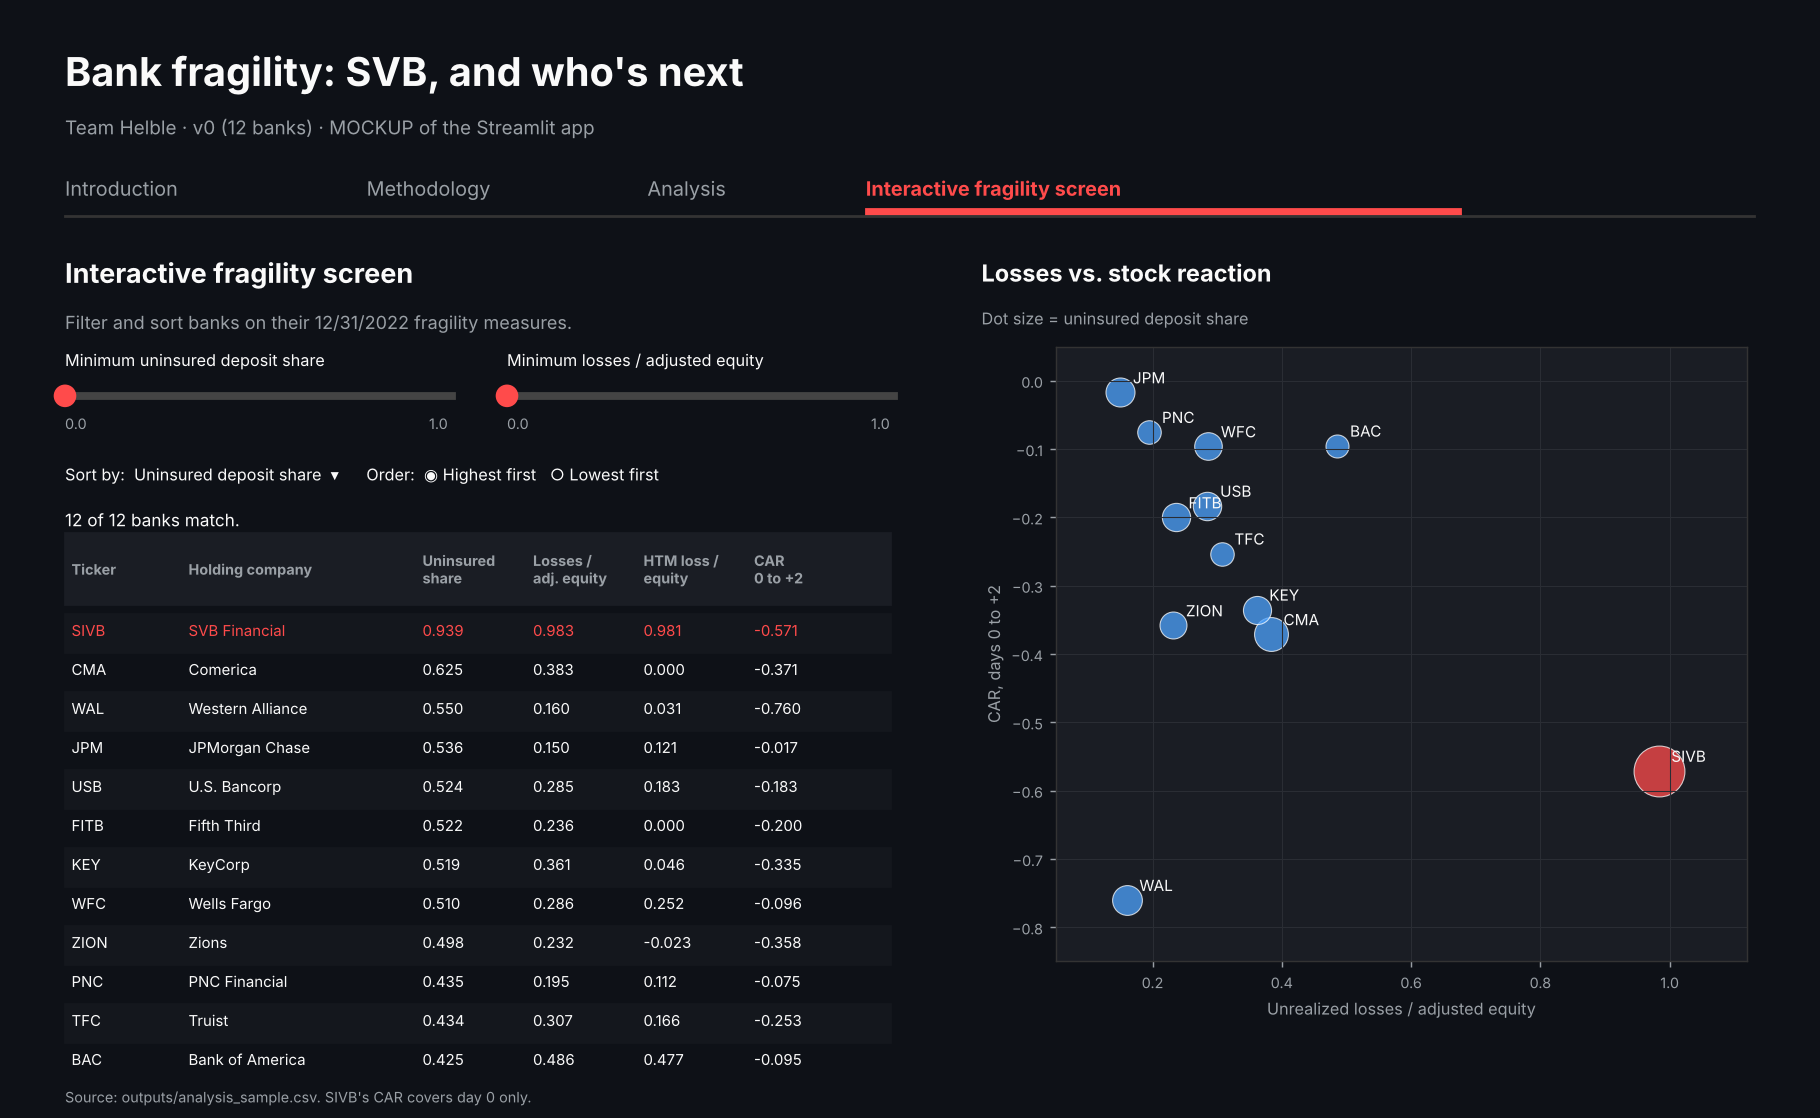


Our public-facing Streamlit dashboard (`app.py`) organizes our findings across four pages:
1. **Overview:** Plain-English summary of the SVB run mechanism and key takeaways for supervisors and investors.
2. **Methodology:** Step-by-step walkthrough of subsidiary aggregation, ratio formulas, and the 2022 market-model event study.
3. **March 2023 Results:** Cross-sectional regression table (`outputs/regression_main.csv`) and interactive scatter plot (`outputs/figures/scatter_loss_vs_car.png`) mapping `unreal_loss_to_adj_equity` against `car_0_2` sized by `uninsured_dep_share`.
4. **Current Bank Fragility Screen:** A sortable, filterable ranking of today's listed U.S. banks using **`09/30/2026` (Q3 2026)** Call Report data.

